# Scraping Berita Saham - ANTARA News (REVISI)
## 7 Emiten LQ45 Sektor Energi | Periode: Januari 2022 - Juni 2026

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45)
Berdasarkan Analisis Sentimen Menggunakan Metode XGBoost dan LSTM

**Penulis**: Ilda Nurida (NRP 6032251068) | **Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Ringkasan perbaikan dibanding versi lama

| # | Masalah lama | Perbaikan di notebook ini |
|---|---|---|
| 1 | Pagination mati di halaman 1 (`?offset=` diabaikan server) | **Auto-deteksi skema** pagination (`page`/`offset`/path) + berhenti berbasis deteksi-perubahan-halaman |
| 2 | Selector body kemungkinan stale -> body sampah -> F4 = 0 | **Auto-deteksi selector body** saat runtime + fallback klaster `<p>` terpanjang |
| 3 | Filter F3 & F4 (AND keras) -> lolos 0% | Gate emiten wajib + konteks pasar jadi **skor**, bukan gerbang keras |
| 4 | Keyword majemuk 3 kata -> 0 hasil | Keyword pencarian **dipendekkan** (recall tinggi); relevansi diserahkan ke filter |
| 5 | Fetch detail tiap kandidat hanya untuk tanggal | Satu fetch -> tanggal **dan** body sekaligus |

> **PENTING**: jalankan **Bagian 6 (Probe)** sebelum Bagian 8 (Scraping).
> Probe akan mencetak skema pagination & selector body yang benar, lalu
> menyimpannya ke variabel global yang dipakai scraper.

## 1. Install Library

In [1]:
!pip install -q tqdm requests beautifulsoup4 lxml pandas
print("Library berhasil diinstall")

Library berhasil diinstall



[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Library & Konfigurasi

In [2]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup as bs
from datetime import datetime, timedelta, timezone
import time, random, re
import pandas as pd
from pathlib import Path
from tqdm import tqdm

WIB = timezone(timedelta(hours=7))

start_date = datetime(2022, 1, 1, tzinfo=WIB)
end_date   = datetime(2026, 6, 30, 23, 59, 59, tzinfo=WIB)

OUTPUT_DIR           = Path('../../03_dataset/raw')
OUTPUT_DIR_DASHBOARD = Path('../../dashboard/data')
CHECKPOINT_DIR       = Path('checkpoint_antara')
for d in (OUTPUT_DIR, OUTPUT_DIR_DASHBOARD, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / 'berita_antara_lq45_energi.csv'
BASE_URL    = 'https://www.antaranews.com'

print("Konfigurasi siap")
print(f"Periode : {start_date:%d %B %Y} s/d {end_date:%d %B %Y}")
print(f"Output  : {OUTPUT_FILE}")

Konfigurasi siap
Periode : 01 January 2022 s/d 30 June 2026
Output  : ..\..\03_dataset\raw\berita_antara_lq45_energi.csv


## 3. Daftar 7 Emiten: Keyword Pencarian vs Alias Filter

Dua kamus dipisah dengan sengaja:
- **`SEARCH_KEYWORDS`** -> dilempar ke mesin pencari ANTARA. Pendek (1-2 kata) demi *recall* tinggi.
- **`EMITEN_ALIAS`** -> dipakai filter F4 untuk memastikan artikel benar-benar menyebut emiten.

Keyword majemuk panjang (mis. "Adaro Minerals bauksit") sengaja **dihapus** karena
pencarian ketat ANTARA membuatnya nyaris selalu nihil hasil.

In [3]:
# Keyword PENCARIAN -> recall tinggi, biar filter yang menyaring
SEARCH_KEYWORDS = {
    'ADRO': ['Adaro', 'Alamtri', 'ADRO'],
    'ADMR': ['Adaro Minerals', 'ADMR'],
    'ITMG': ['Indo Tambangraya', 'ITMG', 'ITM'],
    'PTBA': ['Bukit Asam', 'PTBA'],
    'MEDC': ['Medco', 'MEDC'],
    'AKRA': ['AKR Corporindo', 'AKRA'],
    'PGAS': ['PGN', 'Perusahaan Gas Negara', 'PGAS'],
}

# Alias untuk FILTER F4 (deteksi sebutan emiten). Spasi di akhir alias pendek
# (mis. 'akr ', 'itm ') mencegah salah-cocok dengan kata lain.
EMITEN_ALIAS = {
    'ADRO': ['adro', 'adaro energy', 'adaro', 'alamtri'],
    'ADMR': ['admr', 'adaro minerals'],
    'ITMG': ['itmg', 'indo tambangraya', 'tambangraya', 'itm '],
    'PTBA': ['ptba', 'bukit asam'],
    'MEDC': ['medc', 'medco'],
    'AKRA': ['akra', 'akr corporindo', 'akr '],
    'PGAS': ['pgas', 'perusahaan gas negara', 'pgn'],
}

NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk (Alamtri Resources Indonesia Tbk)',
    'ADMR': 'Adaro Minerals Indonesia Tbk',
    'ITMG': 'Indo Tambangraya Megah Tbk',
    'PTBA': 'Bukit Asam Tbk',
    'MEDC': 'Medco Energi Internasional Tbk',
    'AKRA': 'AKR Corporindo Tbk',
    'PGAS': 'Perusahaan Gas Negara Tbk',
}

URUTAN_EMITEN = list(SEARCH_KEYWORDS.keys())
print(f"Total emiten           : {len(SEARCH_KEYWORDS)}")
print(f"Total keyword pencarian: {sum(len(v) for v in SEARCH_KEYWORDS.values())}")
for k, v in SEARCH_KEYWORDS.items():
    print(f"  {k}: {v}")

Total emiten           : 7
Total keyword pencarian: 17
  ADRO: ['Adaro', 'Alamtri', 'ADRO']
  ADMR: ['Adaro Minerals', 'ADMR']
  ITMG: ['Indo Tambangraya', 'ITMG', 'ITM']
  PTBA: ['Bukit Asam', 'PTBA']
  MEDC: ['Medco', 'MEDC']
  AKRA: ['AKR Corporindo', 'AKRA']
  PGAS: ['PGN', 'Perusahaan Gas Negara', 'PGAS']


## 4. Filter Relevansi (revisi)

Logika baru: **sebutan emiten = gerbang wajib** (mencegah *false positive* seperti
berita IHSG umum). Konteks pasar dihitung sebagai **skor**, bukan gerbang keras,
sehingga berita korporasi yang menyebut emiten di judul tetap lolos.

In [4]:
# F1: URL non-artikel yang dibuang
TIPE_BUANG_URL = [
    '/foto/', '/video/', '/infografis/', '/infografik/', '/galeri/',
    '/kolom/', '/tag/', '/olahraga/', '/antarafoto',
    'otomotif.antaranews', 'ramadhan.antaranews',
]
def filter_url(link):
    l = str(link).lower()
    if '/berita/' not in l:
        return False
    return not any(t in l for t in TIPE_BUANG_URL)

# F2: blacklist headline (politik DIHAPUS dari blacklist - bisa relevan ke volatilitas)
KATA_BUANG_HEADLINE = [
    'wisata', 'liburan', 'hotel', 'kuliner', 'resep', 'makanan',
    'fashion', 'skincare', 'film', 'artis', 'gosip', 'musik',
    'konser', 'drakor', 'bola', 'liga', 'pertandingan',
    'tips kesehatan', 'penyakit', 'vaksin', 'horoskop', 'zodiak',
]
def filter_headline(headline):
    h = str(headline).lower()
    return not any(k in h for k in KATA_BUANG_HEADLINE)

# Kata konteks pasar (untuk SKOR, bukan gerbang keras)
KATA_KONTEKS_SAHAM = [
    'saham', 'bursa', 'bei', 'idx', 'ihsg', 'emiten', 'investor',
    'laba', 'rugi', 'pendapatan', 'revenue', 'kinerja', 'keuangan',
    'kuartal', 'dividen', 'buyback', 'merger', 'akuisisi',
    'rights issue', 'right issue', 'ipo', 'target harga', 'rekomendasi',
    'analis', 'sekuritas', 'valuasi', 'harga saham', 'koreksi',
    'menguat', 'melemah', 'melesat', 'produksi', 'batubara', 'batu bara',
    'minyak', 'gas', 'lifting', 'laba bersih', 'net profit',
    'pasar modal', 'obligasi', 'rupst', 'capex', 'ekspor', 'penjualan',
]

def lolos_relevansi(kode, headline, isi):
    '''Return (bool, alasan). Gate wajib: emiten disebut.'''
    teks_full = (str(headline) + ' ' + str(isi)).lower()
    alias = EMITEN_ALIAS.get(kode, [kode.lower()])

    if not any(a in teks_full for a in alias):
        return False, 'tidak_sebut_emiten'

    n_konteks = sum(1 for k in KATA_KONTEKS_SAHAM if k in teks_full)
    sebut_di_headline = any(a in str(headline).lower() for a in alias)

    if n_konteks >= 1 or sebut_di_headline:
        return True, f'ok(konteks={n_konteks})'
    return False, 'emiten_disebut_konteks_lemah'

print("Filter F1, F2, dan lolos_relevansi() siap")

Filter F1, F2, dan lolos_relevansi() siap


## 5. HTTP Session, Parser Tanggal, Ekstraktor Body & Tanggal

In [5]:
USER_AGENTS = [
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36',
    'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:124.0) Gecko/20100101 Firefox/124.0',
]
def get_headers():
    return {
        'User-Agent'     : random.choice(USER_AGENTS),
        'Accept'         : 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
        'Accept-Language': 'id-ID,id;q=0.9,en-US;q=0.8,en;q=0.7',
        'Referer'        : 'https://www.antaranews.com/',
    }
def buat_session():
    s = requests.Session()
    retry = Retry(total=4, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
    s.mount('https://', HTTPAdapter(max_retries=retry))
    return s
sess = buat_session()

def safe_get(url, timeout=25, max_retry=3):
    global sess
    for attempt in range(1, max_retry + 1):
        try:
            r = sess.get(url, headers=get_headers(), timeout=timeout)
            if r.status_code == 429:
                wait = 60 * attempt
                print(f"  Rate-limit 429 - tunggu {wait}s..."); time.sleep(wait)
                sess = buat_session(); continue
            return r
        except requests.exceptions.ConnectionError as e:
            print(f"  ConnectionError ({attempt}/{max_retry}): {str(e)[:60]}")
            time.sleep(10 * attempt); sess = buat_session()
        except requests.exceptions.Timeout:
            time.sleep(5 * attempt)
        except Exception as e:
            print(f"  Error: {e}"); return None
    return None

def parse_date_antara(raw):
    if not raw: return None
    raw = str(raw).strip()
    try:
        return datetime.fromisoformat(raw)
    except Exception:
        pass
    m = re.search(r'(\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2})', raw)
    if m:
        try:
            return datetime.fromisoformat(m.group(1)).replace(tzinfo=WIB)
        except Exception:
            pass
    return None

NOISE_ANTARA = [
    'Baca juga:', 'Baca Juga:', 'BACA JUGA:', 'Pewarta:', 'Editor:',
    'COPYRIGHT ', 'Antara News', 'antaranews.com',
]
def clean_text(text):
    for n in NOISE_ANTARA:
        text = text.replace(n, '')
    return re.sub(r'\s{2,}', ' ', text).strip()

# Selector body kandidat. DETECTED_BODY_SEL diisi oleh Probe (Bagian 6).
BODY_SELECTORS = [
    'div.post-content', 'div.wrap__article-detail-content',
    'div.article-content', 'div.post__content', 'div.detail__body-text',
    'div[itemprop="articleBody"]', 'div.txt-artikel', 'article',
]
DETECTED_BODY_SEL = None

def _body_from_soup(soup):
    sels = ([DETECTED_BODY_SEL] if DETECTED_BODY_SEL else []) + BODY_SELECTORS
    for sel in sels:
        if not sel:
            continue
        el = soup.select_one(sel)
        if el:
            ps = el.find_all('p')
            txt = clean_text(' '.join(p.get_text(strip=True) for p in ps)) if ps \
                  else clean_text(el.get_text(' ', strip=True))
            if len(txt) > 300:
                return txt
    # Fallback: gabung <p> panjang (>40 char) di seluruh halaman
    allp = [p.get_text(strip=True) for p in soup.find_all('p')]
    return clean_text(' '.join(p for p in allp if len(p) > 40))

def _date_from_soup(soup):
    meta = soup.find('meta', {'property': 'article:published_time'})
    if meta and meta.get('content'):
        dt = parse_date_antara(meta['content'])
        if dt: return dt
    t = soup.find('time')
    if t:
        dt = parse_date_antara(t.get('datetime', '') or t.get_text())
        if dt: return dt
    return None

def fetch_article(url):
    '''Satu request -> (datetime|None, body_str). Hemat 1 request per artikel.'''
    r = safe_get(url)
    if not r:
        return None, ''
    soup = bs(r.text, 'lxml')
    return _date_from_soup(soup), _body_from_soup(soup)

print("Session, parser, ekstraktor body & tanggal siap")

Session, parser, ekstraktor body & tanggal siap


## 6. PROBE: Auto-deteksi Skema Pagination & Selector Body

**Jalankan sel ini sebelum scraping.** Ia menentukan:
1. Skema pagination yang benar-benar bekerja (`page` query / `offset` / path).
2. Selector body artikel yang valid -> disimpan ke `DETECTED_BODY_SEL`.

Hasil deteksi otomatis dipakai oleh scraper di Bagian 7-8.

In [6]:
import requests as _rq

def build_search_url(kw, scheme, idx):
    '''idx = 0,1,2,... (halaman ke-(idx+1)).'''
    q = _rq.utils.quote(kw)
    if scheme == 'offset':
        return f'{BASE_URL}/search/{q}?offset={idx * 10}'
    if scheme == 'page_query':
        return f'{BASE_URL}/search/{q}?page={idx + 1}'
    if scheme == 'page_path':
        return f'{BASE_URL}/search/{q}/{idx + 1}'
    raise ValueError(scheme)

def extract_listing(soup):
    '''Ambil [(href, title)] unik dari halaman hasil pencarian.'''
    out, seen = [], set()
    for a in soup.find_all('a', href=True):
        href, title = a['href'], a.get_text(strip=True)
        if '/berita/' not in href:
            continue
        if not href.startswith('http'):
            href = BASE_URL + href
        if 'antaranews' not in href or len(title) < 10:
            continue
        if href not in seen:
            seen.add(href); out.append((href, title))
    return out

def detect_scheme(kw='Adaro'):
    print(f"  Menguji skema pagination dengan keyword '{kw}'...")
    for scheme in ['page_query', 'offset', 'page_path']:
        try:
            s1 = {h for h, _ in extract_listing(bs(safe_get(build_search_url(kw, scheme, 0)).text, 'lxml'))}
            s2 = {h for h, _ in extract_listing(bs(safe_get(build_search_url(kw, scheme, 1)).text, 'lxml'))}
            baru = s2 - s1
            status = 'VALID' if (s1 and baru) else 'tidak jalan'
            print(f"    [{scheme:10}] hal1={len(s1):2d} | hal2={len(s2):2d} | baru={len(baru):2d} -> {status}")
            if s1 and baru:
                return scheme
        except Exception as e:
            print(f"    [{scheme:10}] error: {str(e)[:50]}")
    print("    -> Tidak ada skema yang menambah hasil. Fallback ke 'offset' (1 halaman saja).")
    return 'offset'

def detect_body_selector(sample_url):
    global DETECTED_BODY_SEL
    soup = bs(safe_get(sample_url).text, 'lxml')
    print(f"  Menguji selector body pada: {sample_url[:70]}")
    best, best_n = None, 0
    for sel in BODY_SELECTORS:
        el = soup.select_one(sel)
        n = len(el.get_text(strip=True)) if el else 0
        if n > best_n:
            best, best_n = sel, n
        mark = '  <- kandidat' if n > 400 else ''
        print(f"    {sel:38} : {n:5d} char{mark}")
    if best_n > 400:
        DETECTED_BODY_SEL = best
        print(f"  -> Selector body terdeteksi: '{best}' ({best_n} char)")
    else:
        print("  -> Tidak ada selector >400 char; scraper akan pakai fallback klaster <p>.")
    return DETECTED_BODY_SEL

# Jalankan deteksi
PAGINATION_SCHEME = detect_scheme('Adaro')
print(f"\n>> SKEMA PAGINATION DIPAKAI: {PAGINATION_SCHEME}\n")

_contoh = extract_listing(bs(safe_get(build_search_url('Adaro', PAGINATION_SCHEME, 0)).text, 'lxml'))
if _contoh:
    detect_body_selector(_contoh[0][0])
else:
    print("Tidak ada artikel contoh untuk uji selector. Cek koneksi / struktur situs.")

  Menguji skema pagination dengan keyword 'Adaro'...
    [page_query] hal1=31 | hal2=31 | baru=15 -> VALID

>> SKEMA PAGINATION DIPAKAI: page_query

  Menguji selector body pada: https://www.antaranews.com/berita/5564199/mantan-dirut-pertamina-patra
    div.post-content                       :  5261 char  <- kandidat
    div.wrap__article-detail-content       :  5261 char  <- kandidat
    div.article-content                    :     0 char
    div.post__content                      :     0 char
    div.detail__body-text                  :     0 char
    div[itemprop="articleBody"]            :     0 char
    div.txt-artikel                        :     0 char
    article                                :     0 char
  -> Selector body terdeteksi: 'div.post-content' (5261 char)


## 7. Scraper Utama (pagination robust + berhenti adaptif)

Perubahan kunci:
- Pagination berbasis **`PAGINATION_SCHEME`** hasil probe.
- Berhenti saat sebuah halaman **tidak menambah link baru** sebanyak `PATIENCE`
  kali berturut-turut (bukan langsung `break` di kegagalan pertama).
- Satu `fetch_article()` mengambil **tanggal + body** sekaligus.

In [7]:
def scrape_antara(kode, keywords, max_pages=40, patience=2,
                  d_min=1.5, d_max=3.0, checkpoint_dir=CHECKPOINT_DIR):
    checkpoint_file = checkpoint_dir / f'{kode}_checkpoint.csv'
    if checkpoint_file.exists():
        df_ckpt = pd.read_csv(checkpoint_file, encoding='utf-8-sig')
        results = df_ckpt.to_dict('records')
        seen    = set(df_ckpt['Link'].tolist())
        print(f'  Resume checkpoint: {len(results)} artikel')
    else:
        results, seen = [], set()

    stat = dict(kandidat=0, lolos_f1=0, lolos_f2=0, disimpan=0,
                out_of_range=0, body_kosong=0, ditolak_relevansi=0, duplikat=0)

    for kw in keywords:
        print(f'  [{kode}|ANTARA] keyword: "{kw}"')
        empty_streak = 0

        for page_idx in range(max_pages):
            url = build_search_url(kw, PAGINATION_SCHEME, page_idx)
            r = safe_get(url)
            if not r:
                empty_streak += 1
                if empty_streak >= patience: break
                time.sleep(random.uniform(d_min, d_max)); continue

            listing = extract_listing(bs(r.text, 'lxml'))
            baru = [(h, t) for h, t in listing if h not in seen]

            if not baru:
                empty_streak += 1
                if empty_streak >= patience:
                    print(f'    Halaman {page_idx+1}: {patience}x tanpa link baru -> stop keyword')
                    break
                time.sleep(random.uniform(d_min, d_max)); continue
            empty_streak = 0

            for link, title in tqdm(baru, desc=f'    [{kode}] hal {page_idx+1}',
                                    unit='art', leave=False):
                if link in seen:
                    stat['duplikat'] += 1; continue
                stat['kandidat'] += 1
                seen.add(link)

                if not filter_url(link):       continue
                stat['lolos_f1'] += 1
                if not filter_headline(title): continue
                stat['lolos_f2'] += 1

                time.sleep(random.uniform(d_min, d_max))
                dt, body = fetch_article(link)
                if not dt:
                    continue
                if not (start_date <= dt <= end_date):
                    stat['out_of_range'] += 1; continue
                if not body.strip():
                    stat['body_kosong'] += 1; continue

                ok, alasan = lolos_relevansi(kode, title, body)
                if not ok:
                    stat['ditolak_relevansi'] += 1; continue

                results.append({
                    'Sumber': 'ANTARA News', 'Kode_Emiten': kode, 'Keyword': kw,
                    'Headline': title, 'Tanggal': dt.strftime('%Y-%m-%d %H:%M'),
                    'Link': link, 'Isi_Berita': body,
                })
                stat['disimpan'] += 1
                tqdm.write(f'    [{stat["disimpan"]}] {title[:70]}')
                if stat['disimpan'] % 25 == 0:
                    pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')

            time.sleep(random.uniform(d_min, d_max))

    if results:
        pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')

    print(f'\n  STATISTIK [{kode}]  ' + '-'*30)
    for k, v in stat.items():
        print(f'    {k:20}: {v:>6,}')
    print(f'    {"disimpan(baru run)":20}: {stat["disimpan"]:>6,}')
    return results

print("scrape_antara() siap")

scrape_antara() siap


## 8. Jalankan Scraping Semua Emiten

In [8]:
assert 'PAGINATION_SCHEME' in dir(), "Jalankan PROBE (Bagian 6) lebih dulu!"

semua_artikel = []
mulai_jam = datetime.now(WIB)

for kode, keywords in SEARCH_KEYWORDS.items():
    print("\n" + "=" * 65)
    print(f"  {kode} | ANTARA News | {start_date:%b %Y} - {end_date:%b %Y}")
    print(f"  Mulai: {datetime.now(WIB):%H:%M:%S} | Keyword: {len(keywords)}")
    print("=" * 65)

    hasil = scrape_antara(kode, keywords)
    semua_artikel.extend(hasil)

    df_tmp = pd.DataFrame(semua_artikel).drop_duplicates(subset='Link')
    df_tmp.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
    elapsed = (datetime.now(WIB) - mulai_jam).total_seconds() / 60
    print(f"  Auto-save: {len(df_tmp):,} artikel | {elapsed:.1f} menit")
    time.sleep(random.uniform(8, 15))

df_final = pd.DataFrame(semua_artikel).drop_duplicates(subset='Link').reset_index(drop=True)
df_final.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')

total = (datetime.now(WIB) - mulai_jam).total_seconds() / 60
print("\n" + "=" * 65)
print(f"  SELESAI | {total:.1f} menit | {len(df_final):,} artikel")
print("=" * 65)
if len(df_final):
    print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())


  ADRO | ANTARA News | Jan 2022 - Jun 2026
  Mulai: 19:58:33 | Keyword: 3
  Resume checkpoint: 57 artikel
  [ADRO|ANTARA] keyword: "Adaro"


    [ADRO] hal 1:   3%|▎         | 1/31 [00:01<00:55,  1.87s/art]

    [1] Mantan Dirut Pertamina Patra Niaga hadapi sidang vonis korupsi minyak


    [ADRO] hal 1:   6%|▋         | 2/31 [00:03<00:55,  1.90s/art]

    [2] Sidang putusan kasus korupsi eks Direktur PT PIS ditunda besok


    [ADRO] hal 1:  10%|▉         | 3/31 [00:06<01:02,  2.22s/art]

... (2,803 outputs left out)

    [543] PGN salurkan bantuan ke 1.044 anak yatim piatu di Sekayu Banyuasin


    [PGAS] hal 6:  20%|██        | 3/15 [00:06<00:25,  2.09s/art]

    [544] Pertagas sukses uji coba penyaluran minyak perdana proyek pipa Rokan


    Halaman 31: 2x tanpa link baru -> stop keyword

  STATISTIK [PGAS]  ------------------------------
    kandidat            :  1,369
    lolos_f1            :  1,367
    lolos_f2            :  1,351
    disimpan            :    544
    out_of_range        :    345
    body_kosong         :      0
    ditolak_relevansi   :    462
    duplikat            :      0
    disimpan(baru run)  :    544
  Auto-save: 1,701 artikel | 154.2 menit

  SELESAI | 154.4 menit | 1,701 artikel
Kode_Emiten
ADRO    260
ADMR      9
ITMG     48
PTBA    448
MEDC    283
AKRA     54
PGAS    599


## 9. Rekap & Validasi Hasil Akhir

In [9]:
if 'df_final' not in dir() or df_final is None or len(df_final) == 0:
    df_final = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')

df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
print("=" * 65)
print("  REKAP AKHIR - ANTARA NEWS")
print("=" * 65)
print(f"  Total artikel  : {len(df_final):,}")
print(f"  Rentang tanggal: {df_final['Tanggal'].min():%Y-%m-%d} s/d {df_final['Tanggal'].max():%Y-%m-%d}")
print("\nPer emiten:")
print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())
print("\nPer tahun:")
print(df_final.groupby(df_final['Tanggal'].dt.year).size().to_string())

  REKAP AKHIR - ANTARA NEWS
  Total artikel  : 1,701
  Rentang tanggal: 2022-01-04 s/d 2026-06-22

Per emiten:
Kode_Emiten
ADRO    260
ADMR      9
ITMG     48
PTBA    448
MEDC    283
AKRA     54
PGAS    599

Per tahun:
Tanggal
2022    249
2023    294
2024    478
2025    516
2026    164


## 10. Simpan Output dengan Kolom Standar

In [10]:
KOLOM_STANDAR = ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
for k in KOLOM_STANDAR:
    if k not in df_final.columns:
        df_final[k] = ''
df_save = df_final.copy()
df_save['Tanggal'] = df_save['Tanggal'].dt.strftime('%Y-%m-%d %H:%M')
df_save = df_save[KOLOM_STANDAR].drop_duplicates(subset=['Link']).reset_index(drop=True)
df_save.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')

print("=" * 65)
print(f"File disimpan : {OUTPUT_FILE}")
print(f"Total artikel : {len(df_save):,}")
print(f"Kolom         : {list(df_save.columns)}")
print("\nLANGKAH SELANJUTNYA:")
print("  -> Gabungkan dengan CSV Detik, Kontan, Bisnis.com")
print("  -> Lanjut ke notebook Preprocessing & Scoring Sentimen IndoBERT")
print("=" * 65)

File disimpan : ..\..\03_dataset\raw\berita_antara_lq45_energi.csv
Total artikel : 1,701
Kolom         : ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']

LANGKAH SELANJUTNYA:
  -> Gabungkan dengan CSV Detik, Kontan, Bisnis.com
  -> Lanjut ke notebook Preprocessing & Scoring Sentimen IndoBERT


## 11. Grafik Tren Volume Berita per Bulan per Emiten

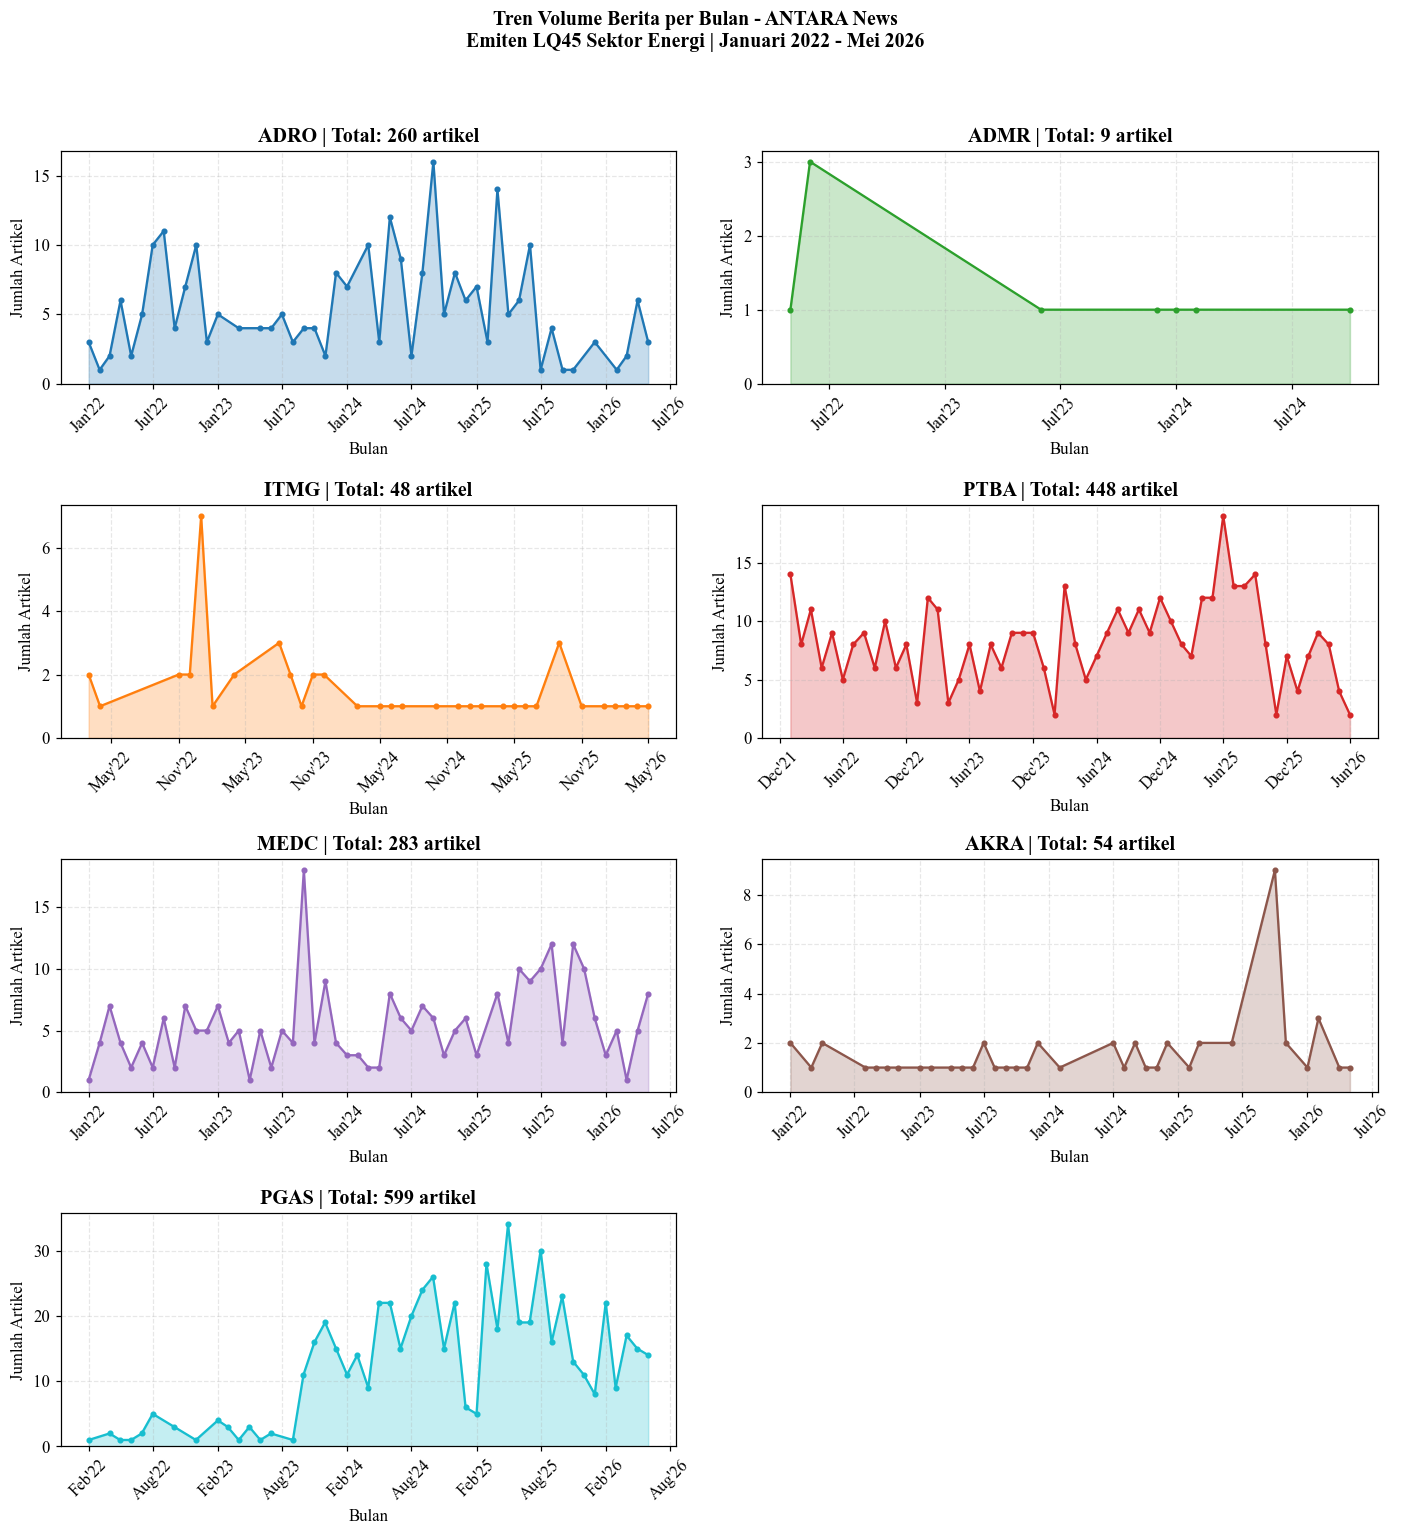

Gambar disimpan: ..\..\dashboard\data\tren_berita_antara_per_emiten.png


In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11, 'figure.dpi': 110})

WARNA = {'ADRO': '#1f77b4', 'ADMR': '#2ca02c', 'ITMG': '#ff7f0e',
          'PTBA': '#d62728', 'MEDC': '#9467bd', 'AKRA': '#8c564b', 'PGAS': '#17becf'}

df_final['Bulan_str'] = df_final['Tanggal'].dt.to_period('M').astype(str)
df_bul = df_final.groupby(['Bulan_str', 'Kode_Emiten']).size().reset_index(name='Jumlah')
df_bul['Bulan_dt'] = pd.to_datetime(df_bul['Bulan_str'])

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    d  = df_bul[df_bul['Kode_Emiten'] == kode].sort_values('Bulan_dt')
    if len(d) > 0:
        ax.fill_between(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode], alpha=0.25)
        ax.plot(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode], linewidth=1.5,
                marker='o', markersize=3)
    total = int(d['Jumlah'].sum()) if len(d) > 0 else 0
    ax.set_title(f"{kode} | Total: {total} artikel", fontweight='bold')
    ax.set_xlabel('Bulan'); ax.set_ylabel('Jumlah Artikel')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y"))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3, linestyle='--'); ax.set_ylim(bottom=0)

axes[-1].axis('off')
fig.suptitle('Tren Volume Berita per Bulan - ANTARA News\n'
             'Emiten LQ45 Sektor Energi | Januari 2022 - Mei 2026',
             fontsize=13, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar = OUTPUT_DIR_DASHBOARD / 'tren_berita_antara_per_emiten.png'
fig.savefig(path_gambar, dpi=150, bbox_inches='tight')
plt.show()
print(f"Gambar disimpan: {path_gambar}")

## 12. Word Cloud Isi Berita per Emiten


[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Total artikel : 1,701
Kode_Emiten
ADRO    260
ADMR      9
ITMG     48
PTBA    448
MEDC    283
AKRA     54
PGAS    599


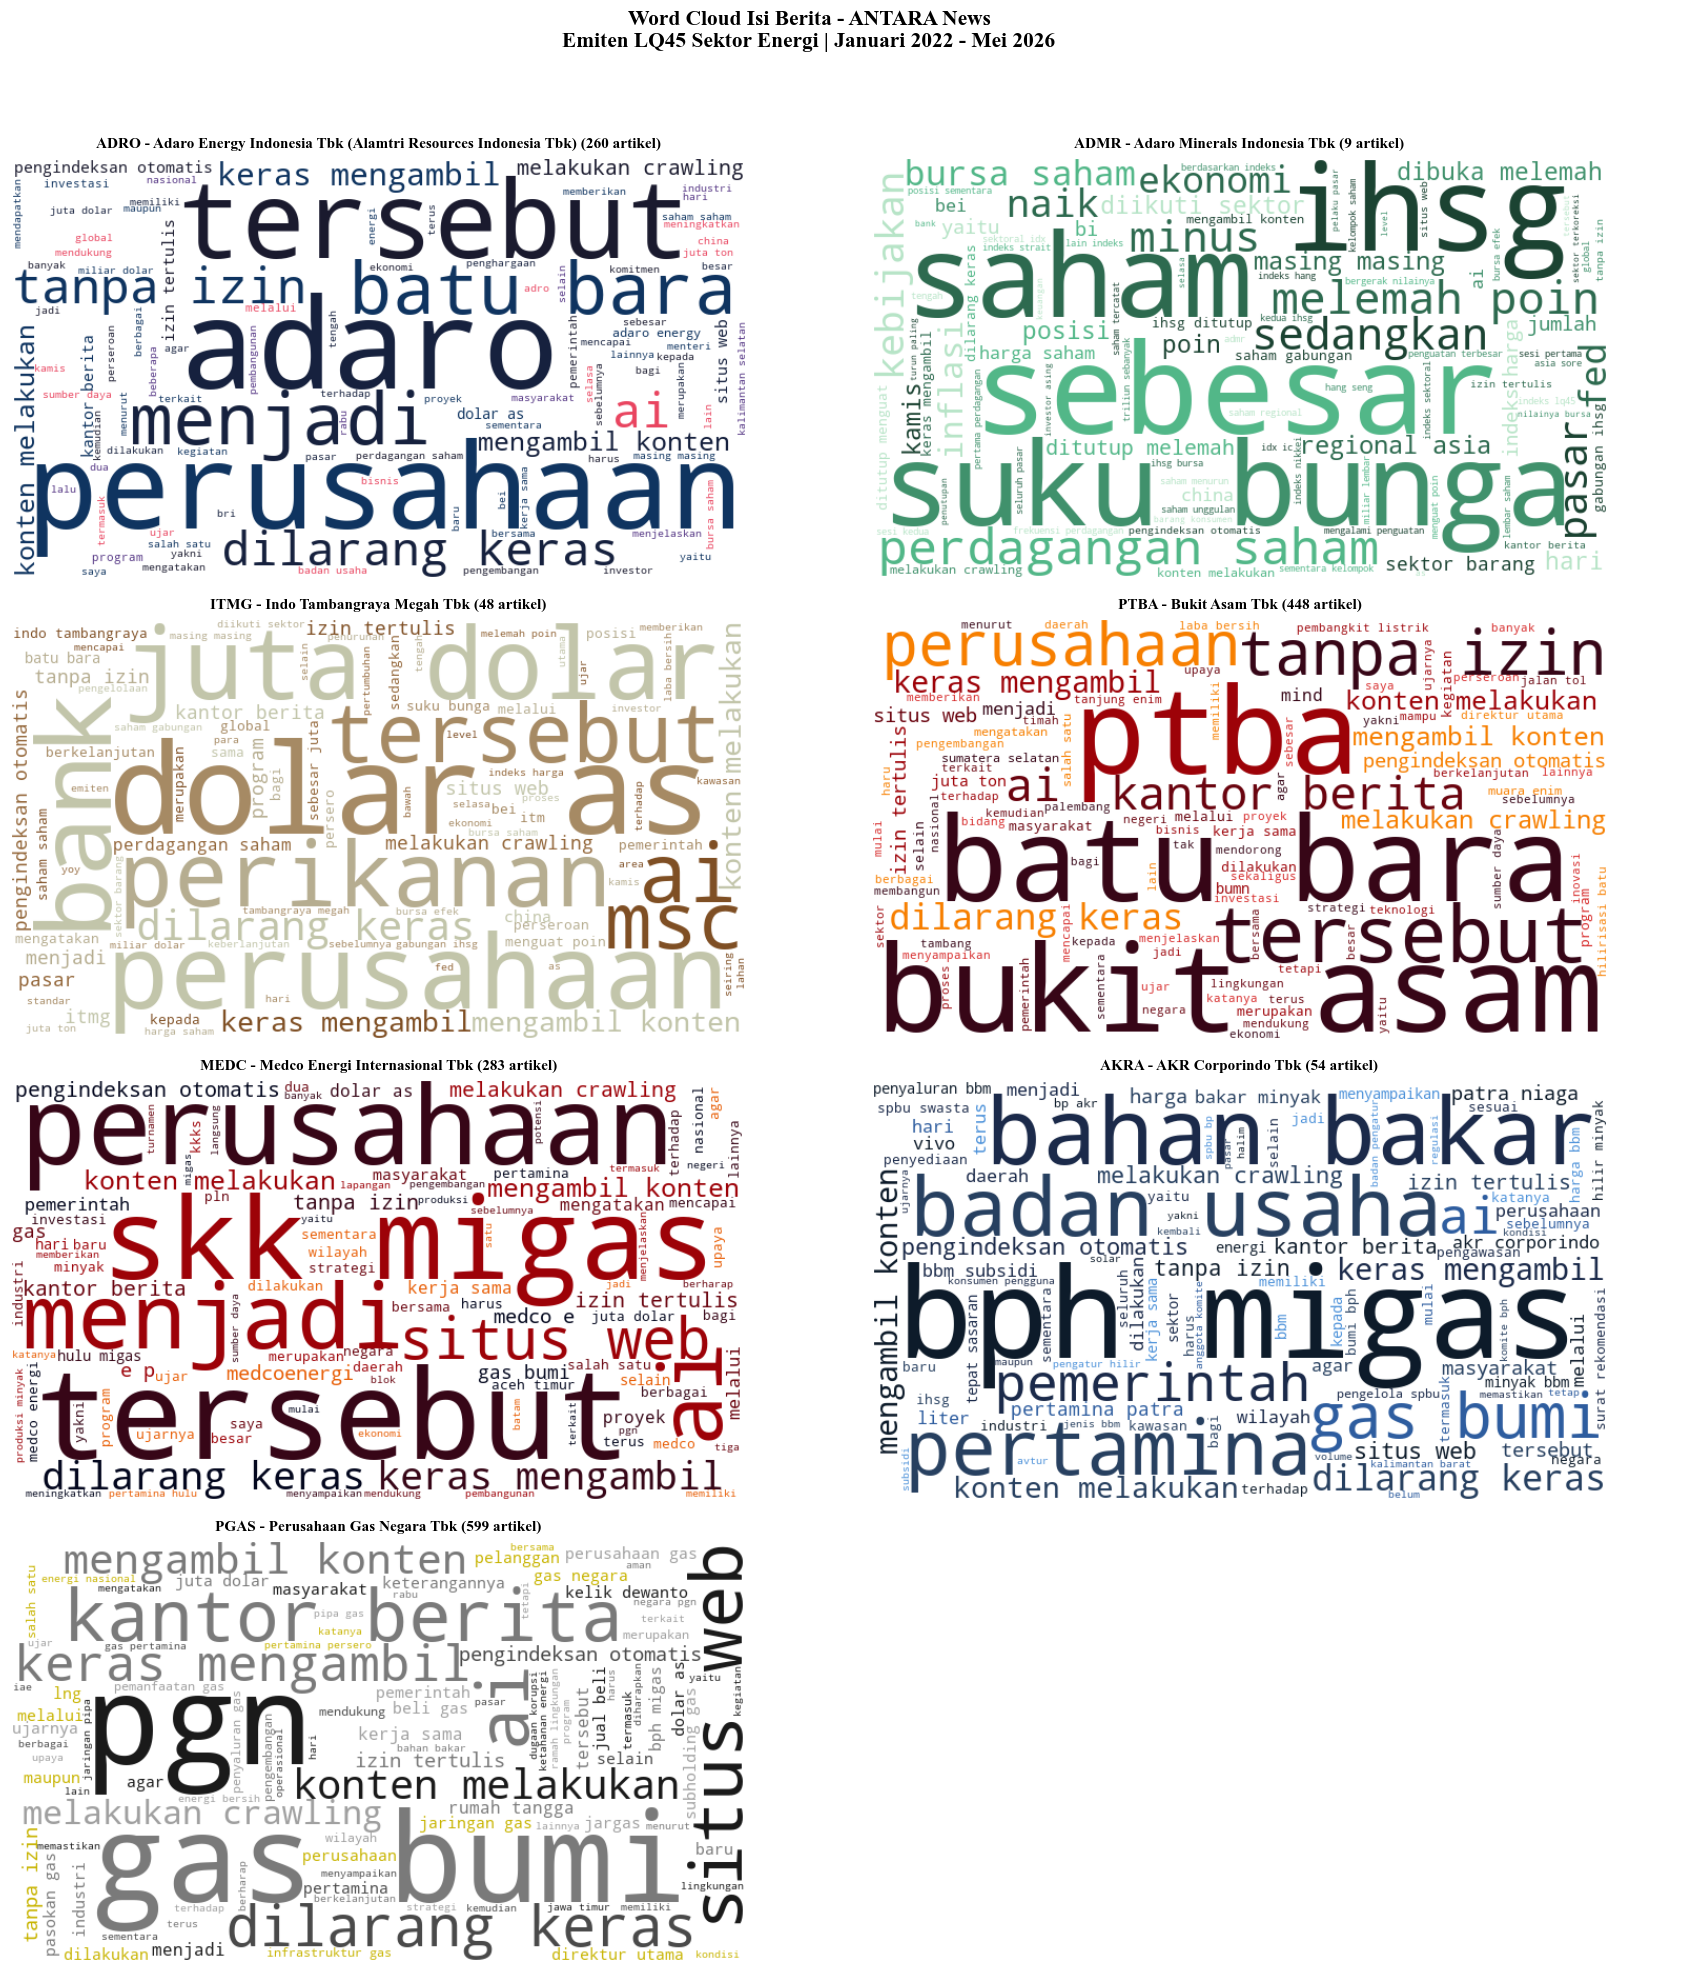

Word cloud disimpan: ..\..\dashboard\data\wordcloud_antara_per_emiten.png


In [12]:
!pip install wordcloud -q

from wordcloud import WordCloud

plt.rcParams.update({'font.family': 'Times New Roman', 'figure.dpi': 110})

PALET_WARNA = {
    'ADRO': ['#1a1a2e', '#16213e', '#0f3460', '#533483', '#e94560'],
    'ADMR': ['#1b4332', '#2d6a4f', '#40916c', '#52b788', '#b7e4c7'],
    'ITMG': ['#7f4f24', '#936639', '#a68a64', '#b6ad90', '#c2c5aa'],
    'PTBA': ['#370617', '#6a040f', '#9d0208', '#d62828', '#f77f00'],
    'MEDC': ['#03071e', '#370617', '#6a040f', '#9d0208', '#e85d04'],
    'AKRA': ['#0d1b2a', '#1b2a4a', '#274060', '#2e5d9f', '#4a90d9'],
    'PGAS': ['#1a1a1a', '#4a4a4a', '#7a7a7a', '#a0a0a0', '#c8b400'],
}

STOPWORDS_ID = {
    'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'dengan', 'untuk',
    'pada', 'adalah', 'dalam', 'tidak', 'juga', 'akan', 'sebagai', 'oleh',
    'atau', 'telah', 'sudah', 'dapat', 'bisa', 'ada', 'saat', 'tahun',
    'kata', 'serta', 'kami', 'kita', 'mereka', 'dia', 'ia', 'lebih',
    'namun', 'karena', 'sehingga', 'hal', 'jika', 'maka', 'antara',
    'baik', 'secara', 'seperti', 'ketika', 'setelah', 'sebelum', 'hingga',
    'sejak', 'selama', 'masih', 'hanya', 'sangat', 'pun',
    'tbk', 'pt', 'rp', 'persen', 'per', 'senilai', 'sekitar',
    'antara', 'news', 'jakarta', 'indonesia', 'co', 'id',
    'said', 'the', 'to', 'of', 'in', 'and', 'atas', 'bahwa',
    'baca', 'juga', 'pewarta', 'editor', 'copyright',
}

if 'df_final' not in dir() or df_final is None:
    df_final = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')
    print(f"Load dari file: {len(df_final)} artikel")

print(f"Total artikel : {len(df_final):,}")
print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()
MIN_ARTIKEL = 5

def make_color_func(palette):
    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        return palette[random_state.randint(0, len(palette) - 1)]
    return color_func

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    df_emiten = df_final[df_final['Kode_Emiten'] == kode]
    n_artikel  = len(df_emiten)
    nama_p     = globals().get('NAMA_PERUSAHAAN', {})

    if n_artikel < MIN_ARTIKEL:
        ax.text(0.5, 0.5, f'Data terlalu sedikit\n({n_artikel} artikel)',
                ha='center', va='center', transform=ax.transAxes, fontsize=11, color='gray')
        ax.set_title(f'{kode} - {nama_p.get(kode, kode)}', fontweight='bold', fontsize=10)
        ax.axis('off'); continue

    teks = ' '.join(df_emiten['Isi_Berita'].dropna().astype(str).str.lower().tolist())
    if not teks.strip():
        ax.text(0.5, 0.5, f'Isi berita kosong\n({kode})', ha='center', va='center',
                transform=ax.transAxes, fontsize=11)
        ax.set_title(f'{kode}', fontweight='bold'); ax.axis('off'); continue

    try:
        wc = WordCloud(width=700, height=400, background_color='white',
                       stopwords=STOPWORDS_ID, max_words=100, min_font_size=8,
                       max_font_size=120, collocations=True, prefer_horizontal=0.7,
                       relative_scaling=0.6,
                       color_func=make_color_func(PALET_WARNA[kode])).generate(teks)
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f'{kode} - {nama_p.get(kode, kode)} ({n_artikel} artikel)',
                     fontweight='bold', fontsize=10, pad=8)
        ax.axis('off')
    except ValueError:
        ax.text(0.5, 0.5, f'Teks terlalu sedikit\nsetelah filtering\n({n_artikel} artikel)',
                ha='center', va='center', transform=ax.transAxes, fontsize=10, color='gray')
        ax.set_title(f'{kode}', fontweight='bold'); ax.axis('off')

axes[-1].axis('off')
fig.suptitle('Word Cloud Isi Berita - ANTARA News\n'
             'Emiten LQ45 Sektor Energi | Januari 2022 - Mei 2026',
             fontsize=14, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])
path_wc = OUTPUT_DIR_DASHBOARD / 'wordcloud_antara_per_emiten.png'
fig.savefig(path_wc, dpi=200, bbox_inches='tight')
plt.show()
print(f"Word cloud disimpan: {path_wc}")

## 13. Simpan Output dengan Kolom Standar

In [1]:
KOLOM_STANDAR = ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
for k in KOLOM_STANDAR:
    if k not in df_final.columns: df_final[k] = ''
df_save = df_final.copy()
df_save['Tanggal'] = df_save['Tanggal'].dt.strftime('%Y-%m-%d %H:%M')
df_save = df_save[KOLOM_STANDAR].drop_duplicates(subset=['Link']).reset_index(drop=True)
df_save.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')

print("=" * 65)
print(f"File diperbarui: {OUTPUT_FILE}")
print(f"  Total artikel : {len(df_save):,}")
print(f"  Kolom         : {list(df_save.columns)}")
print()
print("LANGKAH SELANJUTNYA:")
print("  -> Gabungkan seluruh CSV berita (Detik, Kontan, Bisnis,")
print("     Bloomberg, Warta Ekonomi, ANTARA) pada notebook")
print("     Preprocessing Sentimen IndoBERT untuk scoring sentimen")
print("=" * 65)

NameError: name 'pd' is not defined